# TP Jour 2 — Modèle d'Exécution Spark, Jointures Multi-Datasets & Couche Silver (Delta Lake)

### Objectifs de la séance
1. Observer la **Lazy Evaluation** et distinguer transformations **Narrow** vs **Wide (Shuffle)** sur **Spark Web UI** (`http://localhost:4040`).
2. Profiler la qualité de vos tables **Bronze** (issues d'un ou **plusieurs datasets Kaggle**), nettoyer les anomalies, typer fortement les colonnes et harmoniser les **clés de jointure inter-sources**.
3. Mettre en œuvre une **jointure distribuée multi-datasets maîtrisée** (`BroadcastHashJoin` via `F.broadcast` pour un référentiel/dataset compact, ou `SortMergeJoin` entre deux grandes sources) **en contrôlant la cardinalité (absence d'explosion N-à-M)**.
4. Sauvegarder votre table analytique enrichie dans **`/lakehouse/silver/`** et expérimenter les garanties **ACID de Delta Lake** (`_delta_log`, **Schema Enforcement**, **`MERGE INTO`**, **Time Travel**).
5. Réaliser une analyse exploratoire et des visualisations 1D, 2D et multivariées sur les vols Silver.

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.storagelevel import StorageLevel
from pyspark.errors import AnalysisException
from delta.tables import DeltaTable

spark = (
    SparkSession.builder
    .appName("J2_Spark_Delta_Silver")
    .getOrCreate()
)

spark.conf.set("spark.sql.shuffle.partitions", "50")
print("Session Spark active — Spark UI : http://localhost:4040")

:: loading settings :: url = jar:file:/opt/venv/lib/python3.15/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
io.delta#delta-spark_4.2_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-63114caa-0c4c-4643-9ea1-da7d5f201372;1.0
	confs: [default]


	found io.delta#delta-spark_4.2_2.13;4.4.1 in central
	found io.delta#delta-storage;4.4.1 in central
	found io.unitycatalog#unitycatalog-client;0.6.0 in central


	found org.slf4j#slf4j-api;2.0.13 in central
	found org.apache.logging.log4j#log4j-slf4j2-impl;2.25.3 in central


	found org.apache.logging.log4j#log4j-api;2.25.3 in central
	found com.google.code.findbugs#jsr305;3.0.2 in central
	found io.unitycatalog#unitycatalog-hadoop;0.6.0 in central
	found org.apache.logging.log4j#log4j-core;2.25.3 in central


	found io.delta#delta-kernel-api;4.4.1 in central
	found org.roaringbitmap#RoaringBitmap;0.9.25 in central
	found com.fasterxml.jackson.core#jackson-databind;2.13.5 in central


	found com.fasterxml.jackson.core#jackson-annotations;2.13.5 in central
	found com.fasterxml.jackson.core#jackson-core;2.13.5 in central
	found com.fasterxml.jackson.datatype#jackson-datatype-jdk8;2.13.5 in central
	found org.roaringbitmap#shims;0.9.25 in central
	found io.delta#delta-kernel-defaults;4.4.1 in central
	found org.apache.hadoop#hadoop-client-runtime;3.4.2 in central
	found org.apache.parquet#parquet-hadoop;1.16.0 in central


... (5 outputs left out)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


/opt/venv/lib/python3.15/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


26/11/17 19:27:24 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


Session Spark active — Spark UI : http://localhost:4040


## 1. Chargement de vos tables Bronze (Multi-Datasets / Multi-Tables) & Diagnostic Qualité

### Exercice 1.1 — Charger toutes vos tables Bronze et profiler valeurs manquantes / doublons
1. Chargez dans `bronze_dfs` votre table de faits principale ainsi que la (ou les) table(s) secondaire(s) à joindre depuis `/lakehouse/bronze/<nom_table>`.
2. Comptez le nombre de valeurs `NULL` sur vos colonnes clés (en particulier les **clés de jointure**) ainsi que les doublons éventuels.

In [2]:
BRONZE_TABLES: dict[str, str] = {
    name: f"/lakehouse/bronze/{name}"
    for name in ("flights", "airlines", "airports", "cancellation_codes")
}

bronze_dfs = {alias: spark.read.format("delta").load(path) for alias, path in BRONZE_TABLES.items()}
for alias, df in bronze_dfs.items():
    print(f"[{alias}] {BRONZE_TABLES[alias]} -> {df.count():,} lignes | colonnes : {df.columns[:8]}")

df_bronze = bronze_dfs["flights"]
quality_columns = ["year", "month", "day", "airline", "flight_number", "origin_airport", "destination_airport", "departure_delay", "arrival_delay", "cancellation_reason"]
null_report = df_bronze.select(*[F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in quality_columns])
print("Valeurs nulles dans les colonnes principales :")
null_report.show(truncate=False)

26/11/17 19:27:41 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


[flights] /lakehouse/bronze/flights -> 5,819,079 lignes | colonnes : ['year', 'month', 'day', 'day_of_week', 'airline', 'flight_number', 'tail_number', 'origin_airport']


[airlines] /lakehouse/bronze/airlines -> 14 lignes | colonnes : ['iata_code', 'airline', '_ingested_at', '_source_dataset', '_source_file']


[airports] /lakehouse/bronze/airports -> 322 lignes | colonnes : ['iata_code', 'airport', 'city', 'state', 'country', 'latitude', 'longitude', '_ingested_at']


[cancellation_codes] /lakehouse/bronze/cancellation_codes -> 4 lignes | colonnes : ['cancellation_reason', 'cancellation_description', '_ingested_at', '_source_dataset', '_source_file']
Valeurs nulles dans les colonnes principales :


+----+-----+---+-------+-------------+--------------+-------------------+---------------+-------------+-------------------+
|year|month|day|airline|flight_number|origin_airport|destination_airport|departure_delay|arrival_delay|cancellation_reason|
+----+-----+---+-------+-------------+--------------+-------------------+---------------+-------------+-------------------+
|0   |0    |0  |0      |0            |0             |0                  |86153          |105071       |5729195            |
+----+-----+---+-------+-------------+--------------+-------------------+---------------+-------------+-------------------+



## 2. Harmonisation Inter-Datasets, Nettoyage & Jointure Distribuée (`BroadcastHashJoin` / `SortMergeJoin`)

### Bonnes pratiques de jointure entre plusieurs datasets hétérogènes :
1. **Harmonisation des clés de jointure (*Key Alignment*)** : deux datasets Kaggle d'auteurs différents n'ont presque jamais exactement le même format de clé :
   - *Axe temporel* : ramenez les horodatages à la même granularité et au même fuseau (`F.to_date(...)`, `F.date_trunc("hour", ...)` ou format `yyyy-MM`).
   - *Axe géographique / catégoriel* : normalisez la casse, les espaces et les codes (`F.upper(F.trim(col))`, code ISO pays/région, code postal ou grille `F.round(lat, 2)`).
2. **Prévention des explosions N-à-M** : avant un `LEFT JOIN` de la table principale (`N` lignes) vers un second dataset, assurez-vous que la clé de jointure est **unique côté table secondaire** via une pré-agrégation métier (`groupBy(join_keys).agg(...)`) ou `dropDuplicates(join_keys)` ! Vérifiez systématiquement que le nombre de lignes après `LEFT JOIN` n'explose pas.
3. **Choix de la stratégie physique Spark** :
   - **Table secondaire compacte (< quelques dizaines de Mo)** : forcez **`F.broadcast(df_sec)`** pour obtenir un `BroadcastHashJoin` sans *Shuffle* de la grande table.
   - **Deux grands datasets volumineux** : laissez Spark exécuter un `SortMergeJoin` distribué (optimisé dynamiquement par *Adaptive Query Execution*).

### Exercice 2.1 — Nettoyer, harmoniser vos clés, joindre vos sources et écrire `/lakehouse/silver/<table_silver>`
1. Nettoyez vos tables (`dropDuplicates`, filtrage d'anomalies, typage fort `F.to_timestamp` / `F.to_date` / numériques) et harmonisez la clé de jointure commune.
2. Créez au moins **2 nouvelles colonnes métier dérivées** (dont idéalement un indicateur combinant vos deux sources !) utiles pour les Jours 3 & 4.
3. Réalisez la jointure (avec `F.broadcast(...)` sur une table de dimension/dataset secondaire compact), contrôlez le **taux de rapprochement (*match rate*)** ainsi que l'absence de duplication N-M, et affichez `.explain("simple")`.
4. Écrivez la table enrichie au format **Delta** dans **`/lakehouse/silver/<votre_table>`**.

Pour les vols : une date invalide ou hors de 1900–2100, une clé ou un numéro de vol manquant, une distance négative ou un indicateur annulé/dérouté invalide entraîne le rejet de la ligne. Les clés textuelles vides ou `null` sont traitées comme manquantes. Les vols annulés et les retards inconnus sont conservés sans imputation : remplacer un retard non observé par une médiane inventerait une mesure. Les doublons sont les lignes identiques sur toutes les colonnes métier normalisées, hors métadonnées d'ingestion ; `flight_id` est le SHA-256 de ces colonnes. Les clés des référentiels doivent être uniques après normalisation.

Silver conserve les motifs d'annulation, même si cette colonne est vide pour la plupart des vols : son absence est attendue pour les vols non annulés. Des indicateurs signalent les retards et motifs manquants et le week-end ; les codes A à D sont encodés en colonnes binaires, avec une colonne pour les autres codes et des valeurs nulles lorsque le motif manque. Le retard à l'arrivée est aussi signalé hors des bornes IQR et mis à l'échelle robuste selon les quartiles des vols non annulés dont le retard est connu. Les valeurs extrêmes ne sont pas supprimées.

Attention : chaque exécution réécrit `/lakehouse/silver/flights_enriched` et `/lakehouse/silver/j2_demo_delta`.

In [3]:
SILVER_MAIN_PATH = "/lakehouse/silver/flights_enriched"

narrow = df_bronze.select("airline", "arrival_delay").filter(F.col("arrival_delay").isNotNull())
wide = narrow.groupBy("airline").agg(F.avg("arrival_delay").alias("mean_arrival_delay"))
print("Transformations créées sans action (lazy evaluation).")
print("Plan narrow :")
narrow.explain("simple")
print("Plan wide : l'Exchange correspond au shuffle de l'agrégation.")
wide.explain("simple")
wide.show(5, truncate=False)

def clean_key(column):
    normalized = F.upper(F.trim(F.col(column)))
    return F.when(normalized.isin("", "NULL"), F.lit(None).cast("string")).otherwise(normalized)

def reference_table(df, key, columns):
    ref = df.select(clean_key(key).alias(key), *[F.col(c) for c in columns]).filter(F.col(key).isNotNull() & (F.col(key) != "")).dropDuplicates()
    duplicates = ref.groupBy(key).count().filter(F.col("count") > 1).count()
    if duplicates:
        raise ValueError(f"Clés ambiguës dans le référentiel {key} : {duplicates}")
    return ref

airlines = reference_table(bronze_dfs["airlines"], "iata_code", ["airline"]).select(F.col("iata_code").alias("airline_key"), F.col("airline").alias("airline_name"))
airports = reference_table(bronze_dfs["airports"], "iata_code", ["airport", "city", "state", "country", "latitude", "longitude"])
cancellations = reference_table(bronze_dfs["cancellation_codes"], "cancellation_reason", ["cancellation_description"]).select(F.col("cancellation_reason").alias("cancel_key"), "cancellation_description")

df_clean = df_bronze
for column in ("year", "month", "day", "day_of_week", "flight_number", "departure_delay", "arrival_delay", "distance", "cancelled", "diverted"):
    df_clean = df_clean.withColumn(column, F.expr(f"try_cast(`{column}` as int)"))
for column in ("airline", "origin_airport", "destination_airport", "cancellation_reason"):
    df_clean = df_clean.withColumn(column, clean_key(column))
date_text = F.format_string("%04d-%02d-%02d", F.col("year"), F.col("month"), F.col("day"))
df_clean = df_clean.withColumn("flight_date", F.try_to_timestamp(date_text, F.lit("yyyy-MM-dd")).cast("date"))
valid = F.col("flight_date").isNotNull() & F.col("year").between(1900, 2100) & F.col("flight_number").isNotNull()
for column in ("airline", "origin_airport", "destination_airport"):
    valid = valid & F.col(column).isNotNull() & (F.col(column) != "")
valid = valid & (F.col("distance").isNull() | (F.col("distance") >= 0))
valid = valid & (F.col("cancelled").isNull() | F.col("cancelled").isin(0, 1)) & (F.col("diverted").isNull() | F.col("diverted").isin(0, 1))
bronze_count = df_bronze.count()
df_clean = df_clean.filter(valid)
valid_count = df_clean.count()
source_columns = [c for c in df_bronze.columns if not c.startswith("_")]
df_clean = df_clean.withColumn("flight_id", F.sha2(F.to_json(F.struct(*[F.col(c) for c in source_columns]), {"ignoreNullFields": "false"}), 256))
df_unique = df_clean.dropDuplicates(["flight_id"]).persist(StorageLevel.DISK_ONLY)

try:
    count_before_join = df_unique.count()
    print(f"Lignes Bronze : {bronze_count:,} | invalides : {bronze_count - valid_count:,} | doublons exacts : {valid_count - count_before_join:,}")
    quantiles = df_unique.filter((F.col("cancelled") == 0) & F.col("arrival_delay").isNotNull()).approxQuantile("arrival_delay", [0.25, 0.5, 0.75], 0.0001)
    if len(quantiles) != 3 or quantiles[2] <= quantiles[0]:
        raise ValueError("Impossible de calculer les indicateurs robustes : quartiles absents ou IQR nul.")
    q1, median, q3 = quantiles
    iqr = q3 - q1
    print(f"Retard à l'arrivée : Q1 = {q1}, médiane = {median}, Q3 = {q3}, IQR = {iqr} minutes.")
    airport_details = ("city", "state", "country", "latitude", "longitude")
    origin = airports.select(F.col("iata_code").alias("origin_key"), F.col("airport").alias("origin_airport_name"), *[F.col(c).alias(f"origin_{c}") for c in airport_details])
    destination = airports.select(F.col("iata_code").alias("destination_key"), F.col("airport").alias("destination_airport_name"), *[F.col(c).alias(f"destination_{c}") for c in airport_details])
    df_silver = (
        df_unique.join(F.broadcast(airlines), df_unique.airline == airlines.airline_key, "left").drop("airline_key")
        .join(F.broadcast(origin), F.col("origin_airport") == F.col("origin_key"), "left").drop("origin_key")
        .join(F.broadcast(destination), F.col("destination_airport") == F.col("destination_key"), "left").drop("destination_key")
        .join(F.broadcast(cancellations), F.col("cancellation_reason") == F.col("cancel_key"), "left").drop("cancel_key")
        .withColumn("is_arrival_delayed_15min", F.when(F.col("arrival_delay").isNotNull(), F.col("arrival_delay") >= 15))
        .withColumn("delay_per_100_miles", F.when(F.col("distance") > 0, F.col("arrival_delay") * 100.0 / F.col("distance")))
        .withColumn("arrival_delay_missing", F.col("arrival_delay").isNull())
        .withColumn("departure_delay_missing", F.col("departure_delay").isNull())
        .withColumn("cancellation_reason_missing", F.col("cancellation_reason").isNull())
        .withColumn("is_weekend", F.dayofweek("flight_date").isin(1, 7))
        .withColumn("arrival_delay_outlier_iqr", F.when(F.col("arrival_delay").isNotNull(), (F.col("arrival_delay") < q1 - 1.5 * iqr) | (F.col("arrival_delay") > q3 + 1.5 * iqr)))
        .withColumn("arrival_delay_robust_scaled", F.when(F.col("arrival_delay").isNotNull(), (F.col("arrival_delay") - median) / iqr))
    )
    for code in ("A", "B", "C", "D"):
        df_silver = df_silver.withColumn(f"cancellation_reason_is_{code}", F.when(F.col("cancellation_reason").isNotNull(), (F.col("cancellation_reason") == code).cast("int")))
    df_silver = df_silver.withColumn("cancellation_reason_is_other", F.when(F.col("cancellation_reason").isNotNull(), (~F.col("cancellation_reason").isin("A", "B", "C", "D")).cast("int")))
    print("Plan de jointure :")
    df_silver.explain("simple")
    df_silver.write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(SILVER_MAIN_PATH)
finally:
    df_unique.unpersist()

silver = spark.read.format("delta").load(SILVER_MAIN_PATH)
silver_count = silver.count()
assert silver_count == count_before_join, f"Cardinalité modifiée : {count_before_join:,} avant, {silver_count:,} après jointure."
print(f"Table Silver : {silver_count:,} lignes ; cardinalité préservée.")
silver.select(*[F.round(F.avg(F.col(c).isNotNull().cast("double")) * 100, 2).alias(c + "_match_pct") for c in ("airline_name", "origin_airport_name", "destination_airport_name")]).show(truncate=False)
silver.filter(F.col("cancelled") == 1).select(F.round(F.avg(F.col("cancellation_description").isNotNull().cast("double")) * 100, 2).alias("cancellation_match_pct")).show(truncate=False)

Transformations créées sans action (lazy evaluation).
Plan narrow :


== Physical Plan ==
*(1) Filter isnotnull(arrival_delay#22)
+- *(1) ColumnarToRow
   +- FileScan parquet [airline#4,arrival_delay#22] Batched: true, DataFilters: [isnotnull(arrival_delay#22)], Format: Parquet, Location: PreparedDeltaFileIndex(1 paths)[hdfs://namenode:9000/lakehouse/bronze/flights], PartitionFilters: [], PushedFilters: [IsNotNull(arrival_delay)], ReadSchema: struct<airline:string,arrival_delay:int>


Plan wide : l'Exchange correspond au shuffle de l'agrégation.


== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[airline#4], functions=[avg(arrival_delay#22)])
   +- Exchange hashpartitioning(airline#4, 50), ENSURE_REQUIREMENTS, [plan_id=562]
      +- HashAggregate(keys=[airline#4], functions=[partial_avg(arrival_delay#22)])
         +- Filter isnotnull(arrival_delay#22)
            +- FileScan parquet [airline#4,arrival_delay#22] Batched: true, DataFilters: [isnotnull(arrival_delay#22)], Format: Parquet, Location: PreparedDeltaFileIndex(1 paths)[hdfs://namenode:9000/lakehouse/bronze/flights], PartitionFilters: [], PushedFilters: [IsNotNull(arrival_delay)], ReadSchema: struct<airline:string,arrival_delay:int>




+-------+-------------------+
|airline|mean_arrival_delay |
+-------+-------------------+
|MQ     |6.457873460764516  |
|UA     |5.431593935741549  |
|NK     |14.471799501705833 |
|AA     |3.4513721447256764 |
|DL     |0.18675361236390797|
+-------+-------------------+
only showing top 5 rows


Lignes Bronze : 5,819,079 | invalides : 0 | doublons exacts : 0


Retard à l'arrivée : Q1 = -13.0, médiane = -5.0, Q3 = 8.0, IQR = 21.0 minutes.


Plan de jointure :


== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [year#2418, month#2419, day#2420, day_of_week#2421, airline#2428, flight_number#2422, tail_number#6, origin_airport#2429, destination_airport#2430, scheduled_departure#9, departure_time#10, departure_delay#2423, taxi_out#12, wheels_off#13, scheduled_time#14, elapsed_time#15, air_time#16, distance#2425, wheels_on#18, taxi_in#19, scheduled_arrival#20, arrival_time#21, arrival_delay#2424, diverted#2427, cancelled#2426, ... 38 more fields]
   +- BroadcastHashJoin [cancellation_reason#2431], [cancel_key#2417], LeftOuter, BuildRight, false, false
      :- Project [year#2418, month#2419, day#2420, day_of_week#2421, airline#2428, flight_number#2422, tail_number#6, origin_airport#2429, destination_airport#2430, scheduled_departure#9, departure_time#10, departure_delay#2423, taxi_out#12, wheels_off#13, scheduled_time#14, elapsed_time#15, air_time#16, distance#2425, wheels_on#18, taxi_in#19, scheduled_arrival#20, arrival_time#21, 

Table Silver : 5,819,079 lignes ; cardinalité préservée.


+----------------------+-----------------------------+----------------------------------+
|airline_name_match_pct|origin_airport_name_match_pct|destination_airport_name_match_pct|
+----------------------+-----------------------------+----------------------------------+
|100.0                 |91.65                        |91.65                             |
+----------------------+-----------------------------+----------------------------------+



+----------------------+
|cancellation_match_pct|
+----------------------+
|100.0                 |
+----------------------+



## 3. Garanties Transactionnelles ACID de Delta Lake

### Exercice 3.1 — Explorer `_delta_log` et vérifier le *Schema Enforcement*
1. Lisez et affichez les premières lignes du fichier JSON de transaction `00000000000000000000.json` situé dans `{SILVER_MAIN_PATH}/_delta_log/`.
2. Sur une petite table de démonstration séparée, tentez d'insérer (`mode("append")`) un DataFrame au schéma incompatible et interceptez l'exception levée par Delta Lake, sans modifier la table analytique.

In [4]:
spark.read.text(f"{SILVER_MAIN_PATH}/_delta_log/00000000000000000000.json").show(8, truncate=110)

# La démonstration transactionnelle utilise une petite copie pour préserver la table analytique.
SILVER_DEMO_PATH = "/lakehouse/silver/j2_demo_delta"
sample_df = silver.select("flight_id", "flight_date", "airline", "arrival_delay")
sample_rows = sample_df.limit(3).collect()
assert len(sample_rows) == 3, "Au moins trois vols sont nécessaires pour la démonstration Delta."
demo_initial = spark.createDataFrame(sample_rows[:2], sample_df.schema).withColumn("demo_status", F.lit("initial"))
demo_initial.write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(SILVER_DEMO_PATH)
bad_df = spark.createDataFrame([("test_1", "colonne_intruse")], ["fake_id", "intruder_col"])
try:
    bad_df.write.format("delta").mode("append").save(SILVER_DEMO_PATH)
except AnalysisException as error:
    if "schema" not in str(error).lower():
        raise
    print("Schema Enforcement validé : écriture incompatible refusée.")
else:
    raise AssertionError("L'écriture avec un schéma incompatible aurait dû échouer.")

+--------------------------------------------------------------------------------------------------------------+
|                                                                                                         value|
+--------------------------------------------------------------------------------------------------------------+
|{"commitInfo":{"timestamp":1794915962046,"operation":"WRITE","operationParameters":{"mode":"Overwrite","par...|
|{"metaData":{"id":"1895f4ad-75f0-4aa4-a5fd-c81a1272a67e","format":{"provider":"parquet","options":{}},"sche...|
|                                                      {"protocol":{"minReaderVersion":1,"minWriterVersion":2}}|
|{"add":{"path":"part-00000-616ffb23-18f9-43c9-8c3d-564795665804-c000.snappy.parquet","partitionValues":{},"...|
|{"add":{"path":"part-00001-6cb36dcd-c312-41a5-94e2-339b432bdb52-c000.snappy.parquet","partitionValues":{},"...|
|{"add":{"path":"part-00002-f9618803-128a-4da9-9459-8a4cd10ce3ea-c000.snappy.parquet","partition

Schema Enforcement validé : écriture incompatible refusée.


### Exercice 3.2 — Upsert (`MERGE INTO`) et Voyage dans le Temps (`VERSION AS OF`)
1. Prélevez trois vols de la table Silver et créez une petite table Delta de démonstration avec les deux premiers. Appliquez un **`MERGE INTO`** : mise à jour du deuxième et insertion du troisième.
2. Affichez l'historique et comparez la version avant le MERGE à la version courante. La table analytique principale reste inchangée.

In [5]:
target_delta = DeltaTable.forPath(spark, SILVER_DEMO_PATH)
version_before = target_delta.history(1).select("version").first()[0]
updates = spark.createDataFrame(sample_rows[1:], sample_df.schema).withColumn("demo_status", F.lit("merge"))
(target_delta.alias("target").merge(updates.alias("source"), "target.flight_id = source.flight_id")
    .whenMatchedUpdateAll().whenNotMatchedInsertAll().execute())

history_df = target_delta.history()
history_df.select("version", "timestamp", "operation", "operationMetrics").show(truncate=80)
before = spark.read.format("delta").option("versionAsOf", version_before).load(SILVER_DEMO_PATH)
after = spark.read.format("delta").load(SILVER_DEMO_PATH)
before_status = {row.flight_id: row.demo_status for row in before.select("flight_id", "demo_status").collect()}
after_status = {row.flight_id: row.demo_status for row in after.select("flight_id", "demo_status").collect()}
assert len(before_status) == 2 and len(after_status) == 3
assert before_status[sample_rows[1].flight_id] == "initial" and after_status[sample_rows[1].flight_id] == "merge"
assert sample_rows[2].flight_id not in before_status and after_status[sample_rows[2].flight_id] == "merge"
print(f"Time Travel : version {version_before} = 2 lignes ; version courante = 3 lignes (1 mise à jour, 1 insertion).")

26/11/17 19:33:32 WARN MapPartitionsRDD: RDD 409 was locally checkpointed, its lineage has been truncated and cannot be recomputed after unpersisting


+-------+-----------------------+---------+--------------------------------------------------------------------------------+
|version|              timestamp|operation|                                                                operationMetrics|
+-------+-----------------------+---------+--------------------------------------------------------------------------------+
|      5|2026-11-17 19:33:30.092|    MERGE|{numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetBytesRemoved -...|
|      4|2026-11-17 19:33:21.966|    WRITE|{numFiles -> 3, numRemovedFiles -> 2, numRemovedBytes -> 3832, numOutputRows ...|
|      3| 2026-11-17 15:37:27.78|    MERGE|{numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetBytesRemoved -...|
|      2|2026-11-17 15:37:21.721|    WRITE|{numFiles -> 3, numRemovedFiles -> 2, numRemovedBytes -> 3837, numOutputRows ...|
|      1|2026-11-17 11:46:24.506|    MERGE|{numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetBytesRemoved -...|


Time Travel : version 4 = 2 lignes ; version courante = 3 lignes (1 mise à jour, 1 insertion).


## 4. Diagnostic complémentaire et analyse exploratoire (EDA)

Cette section adapte les nouvelles consignes du professeur aux vols. Elle lit Silver sans la réécrire. Les statistiques et profils par compagnie sont calculés sur l'ensemble des données avec Spark ; les graphiques individuels utilisent un échantillon aléatoire reproductible et plafonné avant transfert vers Pandas.

Un retard inconnu, notamment pour un vol annulé, n'est pas assimilé à zéro ni imputé. L'association entre absence de retard et annulation est observable, mais elle ne prouve pas à elle seule un mécanisme MCAR, MAR ou MNAR. Un zéro n'est pas automatiquement une valeur manquante. Les valeurs extrêmes sont signalées, pas supprimées.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import functions as F
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
silver_eda = spark.read.format("delta").load("/lakehouse/silver/flights_enriched")
print("Retards manquants selon le statut d'annulation :")
silver_eda.groupBy("cancelled").agg(
    F.count("*").alias("vols"),
    F.sum(F.col("arrival_delay").isNull().cast("long")).alias("arrivee_manquante"),
    F.sum(F.col("departure_delay").isNull().cast("long")).alias("depart_manquant"),
).orderBy("cancelled").show()
print("Distances manquantes, zéros et dates Epoch (un zéro n'est pas automatiquement manquant) :")
silver_eda.agg(
    F.sum(F.col("distance").isNull().cast("long")).alias("distance_manquante"),
    F.sum((F.col("distance") == 0).cast("long")).alias("distance_zero"),
    F.sum((F.col("flight_date") == F.lit("1970-01-01").cast("date")).cast("long")).alias("dates_epoch"),
).show()
print("Valeurs textuelles vides ou 'null' dans les clés Bronze :")
bronze_eda = spark.read.format("delta").load("/lakehouse/bronze/flights")
keys = ("airline", "origin_airport", "destination_airport")
bronze_eda.select(*[
    F.sum((F.col(c).isNotNull() & F.lower(F.trim(F.col(c))).isin("", "null")).cast("long")).alias(c)
    for c in keys
]).show()

observed = silver_eda.filter((F.col("cancelled") == 0) & F.col("arrival_delay").isNotNull())
stats = observed.agg(
    F.count("*").alias("n"),
    *[F.avg(c).alias(c + "_mean") for c in ("departure_delay", "arrival_delay", "distance")],
    *[F.stddev(c).alias(c + "_std") for c in ("departure_delay", "arrival_delay", "distance")],
    *[F.percentile_approx(c, [0.25, 0.5, 0.75], 10000).alias(c + "_q") for c in ("departure_delay", "arrival_delay", "distance")],
).first()
print(f"Vols non annulés avec retard à l'arrivée connu : {stats['n']:,}")
if stats['n'] < 2:
    raise ValueError("Au moins deux vols observés sont nécessaires pour l'analyse.")
summary = []
for column in ("departure_delay", "arrival_delay", "distance"):
    q1, median, q3 = stats[column + "_q"]
    summary.append({"variable": column, "moyenne": stats[column + "_mean"], "écart-type": stats[column + "_std"], "médiane": median, "Q1": q1, "Q3": q3, "IQR": q3 - q1})
display(pd.DataFrame(summary).round(2))
q1, median, q3 = stats["arrival_delay_q"]
iqr = q3 - q1
mean_delay, std_delay = stats["arrival_delay_mean"], stats["arrival_delay_std"]
if iqr <= 0 or std_delay is None or std_delay <= 0:
    raise ValueError("Impossible de comparer IQR et Z-score : dispersion nulle ou absente.")
print("Valeurs extrêmes du retard à l'arrivée : IQR contre Z-score (aucune suppression)")
observed.agg(
    F.sum(((F.col("arrival_delay") < q1 - 1.5 * iqr) | (F.col("arrival_delay") > q3 + 1.5 * iqr)).cast("long")).alias("hors_bornes_iqr"),
    F.sum((F.abs((F.col("arrival_delay") - mean_delay) / std_delay) > 3).cast("long")).alias("z_score_absolu_sup_3"),
).show()
print(f"Mise à l'échelle robuste : (retard - {median}) / {iqr} ; médiane et IQR calculés sur les vols observés.")

Retards manquants selon le statut d'annulation :


+---------+-------+-----------------+---------------+
|cancelled|   vols|arrivee_manquante|depart_manquant|
+---------+-------+-----------------+---------------+
|        0|5729195|            15187|              0|
|        1|  89884|            89884|          86153|
+---------+-------+-----------------+---------------+

Distances manquantes, zéros et dates Epoch (un zéro n'est pas automatiquement manquant) :


+------------------+-------------+-----------+
|distance_manquante|distance_zero|dates_epoch|
+------------------+-------------+-----------+
|                 0|            0|          0|
+------------------+-------------+-----------+

Valeurs textuelles vides ou 'null' dans les clés Bronze :


+-------+--------------+-------------------+
|airline|origin_airport|destination_airport|
+-------+--------------+-------------------+
|      0|             0|                  0|
+-------+--------------+-------------------+



Vols non annulés avec retard à l'arrivée connu : 5,714,008


,variable,moyenne,écart-type,médiane,Q1,Q3,IQR
0,departure_delay,9.29,36.89,-2,-5,7,12
1,arrival_delay,4.41,39.27,-5,-13,8,21
2,distance,824.46,608.66,650,373,1065,692


Valeurs extrêmes du retard à l'arrivée : IQR contre Z-score (aucune suppression)


+---------------+--------------------+
|hors_bornes_iqr|z_score_absolu_sup_3|
+---------------+--------------------+
|         512002|              110956|
+---------------+--------------------+

Mise à l'échelle robuste : (retard - -5) / 21 ; médiane et IQR calculés sur les vols observés.


### 4.1 Distributions 1D et tri croisé

Histogramme des retards à l'arrivée, volume par compagnie et proportion de vols en retard d'au moins 15 minutes. Le tri croisé compare jours ouvrés et week-ends ; seuls les vols non annulés dont le retard à l'arrivée est connu sont inclus. L'histogramme est limité à −60 à 180 minutes pour la lisibilité ; les statistiques restent calculées sur tous les vols observés.

/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Échantillon reproductible pour les graphiques individuels : 11,556 vols (plafond 15 000).


Tri croisé : pourcentage de vols par jour ouvré / week-end et statut d'arrivée


is_late,Moins de 15 min,15 min ou plus
is_weekend,,
Jour ouvré,80.90,19.10
Week-end,82.76,17.24


/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


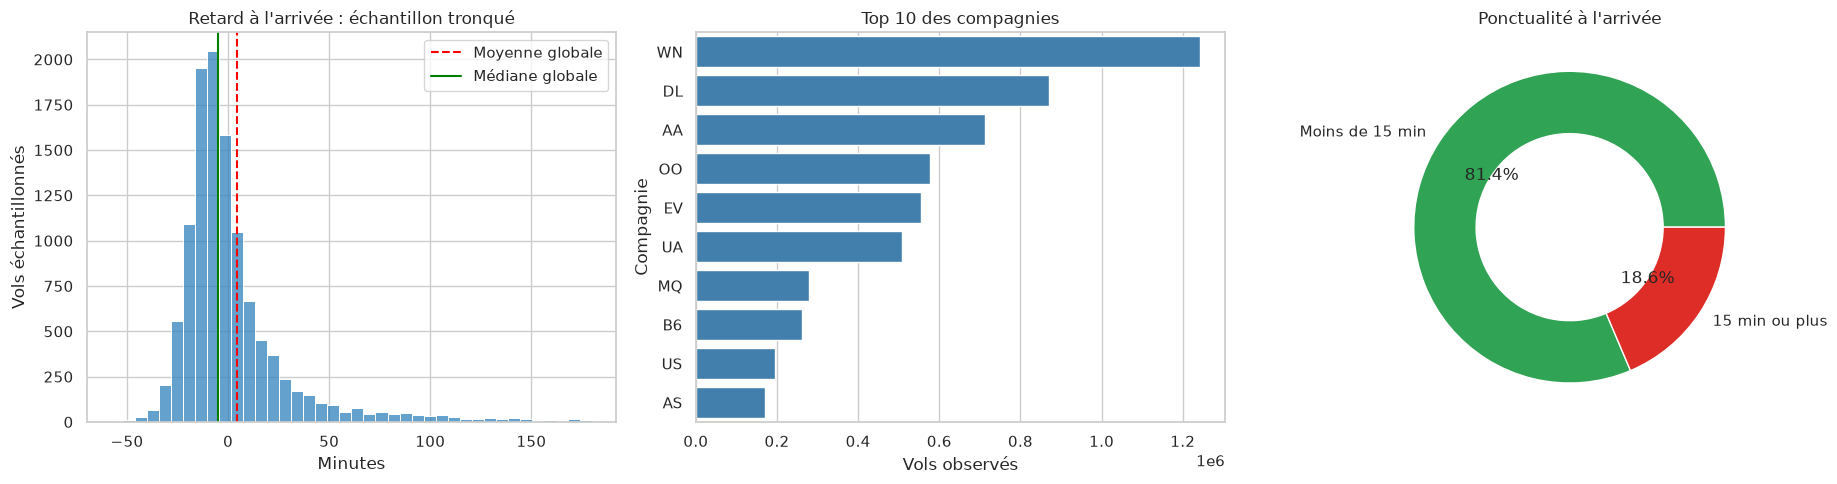

In [7]:
eda_flights = observed.withColumn("is_weekend", F.dayofweek("flight_date").isin(1, 7)).withColumn("is_late", F.col("arrival_delay") >= 15)
sample_pd = (eda_flights.select("flight_date", "airline", "distance", "departure_delay", "arrival_delay", "is_weekend", "is_late")
    .dropna(subset=["distance", "departure_delay", "arrival_delay"])
    .sample(fraction=0.002, seed=42).limit(15000).toPandas())
if len(sample_pd) < 10:
    raise ValueError("Échantillon EDA insuffisant : au moins 10 vols complets sont nécessaires.")
print(f"Échantillon reproductible pour les graphiques individuels : {len(sample_pd):,} vols (plafond 15 000).")
cross = eda_flights.groupBy("is_weekend", "is_late").count().toPandas()
cross_table = cross.pivot(index="is_weekend", columns="is_late", values="count").fillna(0)
cross_pct = cross_table.div(cross_table.sum(axis=1), axis=0).mul(100).round(2)
print("Tri croisé : pourcentage de vols par jour ouvré / week-end et statut d'arrivée")
display(cross_pct.rename(index={False: "Jour ouvré", True: "Week-end"}, columns={False: "Moins de 15 min", True: "15 min ou plus"}))
carrier_counts = eda_flights.groupBy("airline").count().orderBy(F.desc("count")).limit(10).toPandas()
late_counts = eda_flights.groupBy("is_late").count().toPandas().set_index("is_late")["count"].reindex([False, True], fill_value=0)
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
sns.histplot(sample_pd.loc[sample_pd["arrival_delay"].between(-60, 180), "arrival_delay"], bins=40, ax=axes[0], color="#3182bd")
axes[0].axvline(stats["arrival_delay_mean"], color="red", linestyle="--", label="Moyenne globale")
axes[0].axvline(median, color="green", label="Médiane globale")
axes[0].set(title="Retard à l'arrivée : échantillon tronqué", xlabel="Minutes", ylabel="Vols échantillonnés")
axes[0].legend()
sns.barplot(data=carrier_counts, x="count", y="airline", color="#3182bd", ax=axes[1])
axes[1].set(title="Top 10 des compagnies", xlabel="Vols observés", ylabel="Compagnie")
axes[2].pie(late_counts, labels=["Moins de 15 min", "15 min ou plus"], autopct="%1.1f%%", colors=["#31a354", "#de2d26"], wedgeprops={"width": 0.4})
axes[2].set_title("Ponctualité à l'arrivée")
plt.tight_layout()
plt.show()

### 4.2 Segmentation, discrétisation et graphiques 2D

Les volumes et taux mensuels sont calculés par Spark et triés chronologiquement. Les tranches fixes de retard au départ (`cut`), les quartiles de distance (`qcut`) et les boîtes par compagnie utilisent l'échantillon ; les liens observés ne démontrent pas une causalité.

/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Retard à l'arrivée par tranche de départ (échantillon) :


,vols,retard_median,retard_15min_pct
tranche_depart,,,
En avance,6529,-11.0,2.96
0–14 min,2877,-1.0,9.52
15–59 min,1489,23.0,71.19
60 min ou plus,661,97.0,100.00


Quartiles de distance (échantillon) :


,vols,retard_median
quartile_distance,,
"(30.999, 373.0]",2906,-4.0
"(373.0, 651.0]",2879,-5.0
"(651.0, 1072.0]",2884,-6.0
"(1072.0, 4983.0]",2887,-6.0


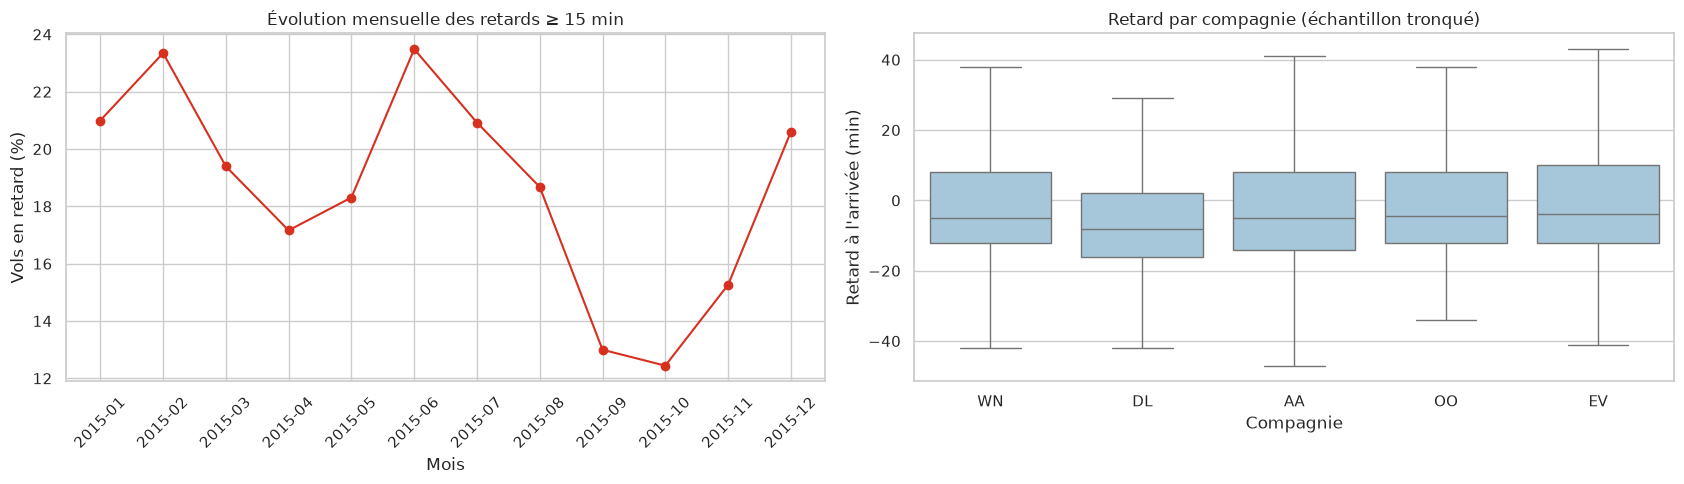

In [8]:
monthly_pd = (eda_flights.groupBy(F.date_format("flight_date", "yyyy-MM").alias("mois"))
    .agg(F.count("*").alias("vols"), (100 * F.avg(F.col("is_late").cast("double"))).alias("retard_pct"))
    .orderBy("mois").toPandas())
sample_pd["tranche_depart"] = pd.cut(sample_pd["departure_delay"], bins=[-np.inf, 0, 15, 60, np.inf], labels=["En avance", "0–14 min", "15–59 min", "60 min ou plus"], right=False)
sample_pd["quartile_distance"] = pd.qcut(sample_pd["distance"], q=4, duplicates="drop")
print("Retard à l'arrivée par tranche de départ (échantillon) :")
display(sample_pd.groupby("tranche_depart", observed=True).agg(vols=("arrival_delay", "size"), retard_median=("arrival_delay", "median"), retard_15min_pct=("is_late", lambda x: 100 * x.mean())).round(2))
print("Quartiles de distance (échantillon) :")
display(sample_pd.groupby("quartile_distance", observed=True).agg(vols=("distance", "size"), retard_median=("arrival_delay", "median")).round(2))
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
axes[0].plot(monthly_pd["mois"], monthly_pd["retard_pct"], marker="o", color="#d7301f")
axes[0].set(title="Évolution mensuelle des retards ≥ 15 min", xlabel="Mois", ylabel="Vols en retard (%)")
axes[0].tick_params(axis="x", rotation=45)
top_airlines = carrier_counts.head(5)["airline"].tolist()
box_sample = sample_pd[sample_pd["airline"].isin(top_airlines) & sample_pd["arrival_delay"].between(-60, 180)]
sns.boxplot(data=box_sample, x="airline", y="arrival_delay", order=top_airlines, ax=axes[1], color="#9ecae1", showfliers=False)
axes[1].set(title="Retard par compagnie (échantillon tronqué)", xlabel="Compagnie", ylabel="Retard à l'arrivée (min)")
plt.tight_layout()
plt.show()

### 4.3 Corrélations, graphiques multidimensionnels et ACP

Pearson mesure la relation linéaire et Spearman la relation monotone sur les rangs : corrélation ne signifie pas causalité. Le pairplot utilise un sous-échantillon ; le bubble plot et l'ACP utilisent les profils agrégés de toutes les compagnies. Les six variables de l'ACP sont standardisées ; la taille des bulles représente le nombre de vols.

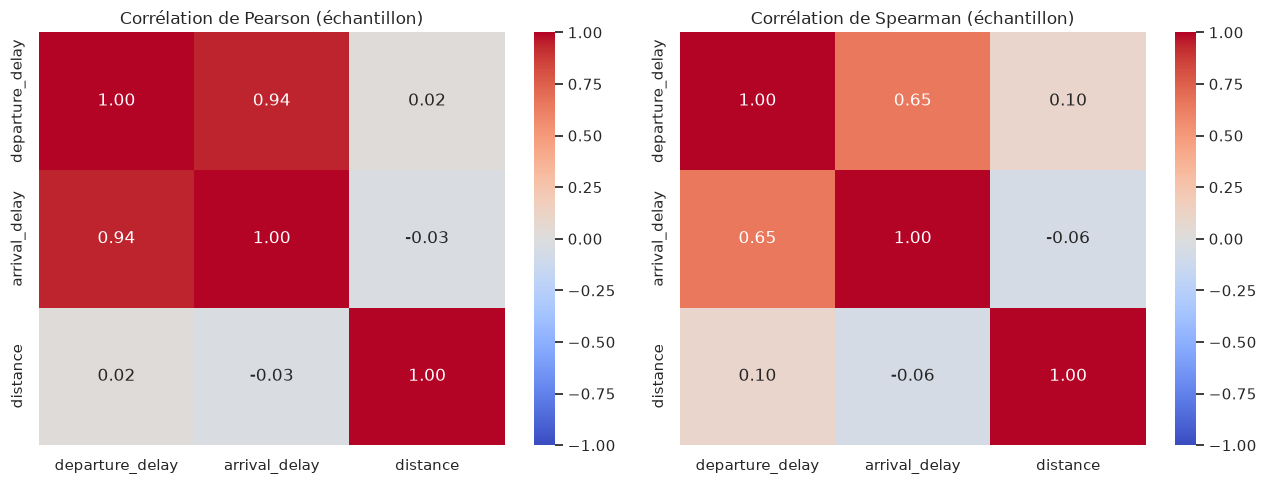

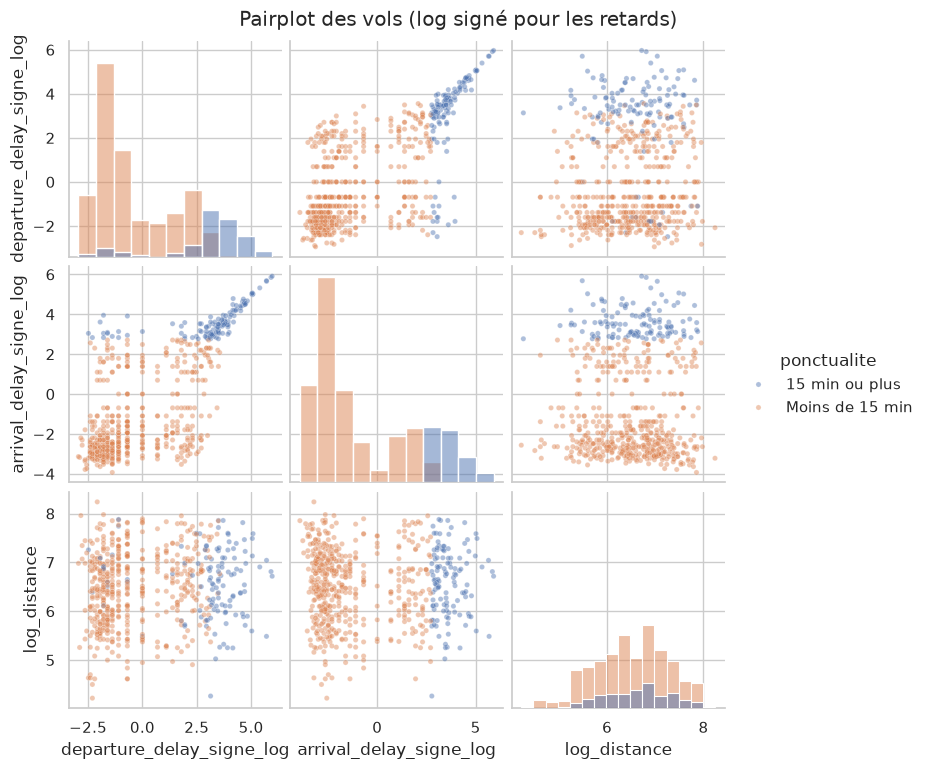

/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


ACP : PC1 = 52.3 %, PC2 = 23.3 %, total = 75.6 % de variance expliquée


,PC1,PC2
depart_moyen,0.459,-0.458
arrivee_moyenne,0.553,-0.027
arrivee_mediane,0.388,0.493
retard_pct,0.543,-0.180
distance_moyenne,0.062,-0.025
weekend_pct,0.186,0.716


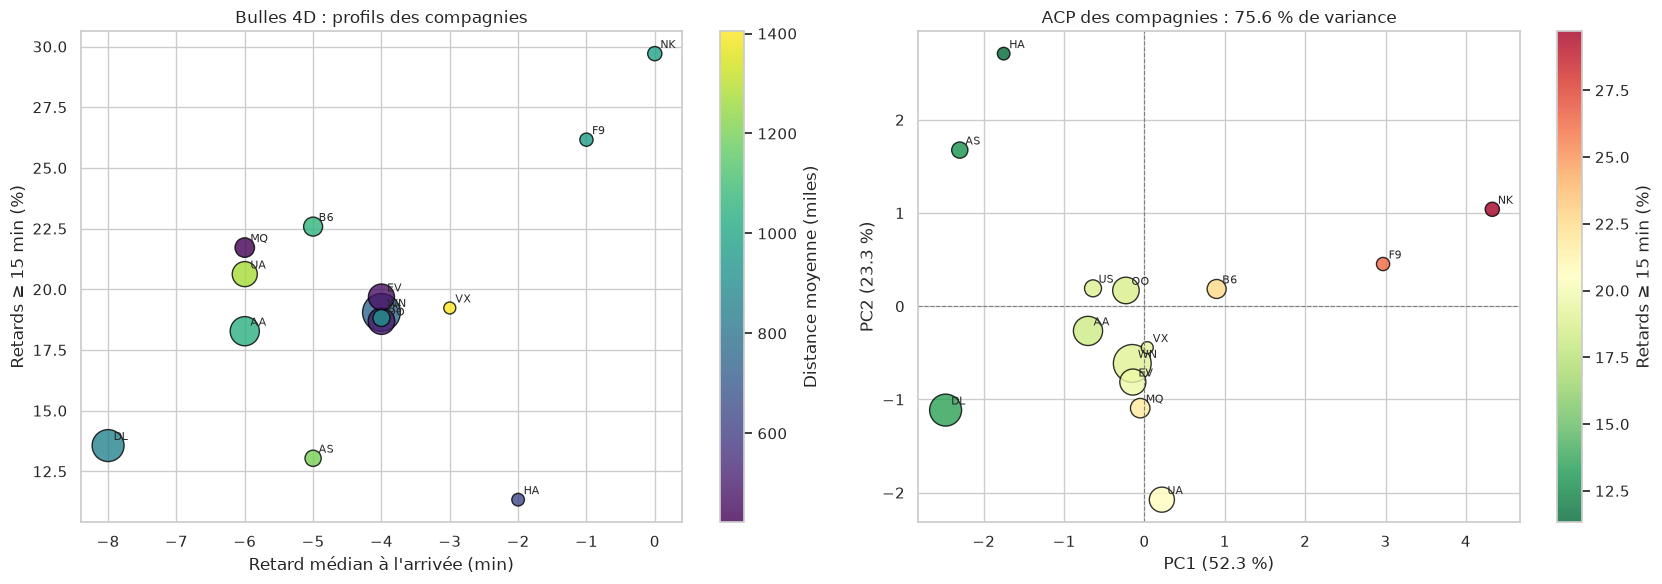

In [9]:
corr_cols = ["departure_delay", "arrival_delay", "distance"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, method in zip(axes, ("pearson", "spearman")):
    sns.heatmap(sample_pd[corr_cols].corr(method=method), annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm", ax=ax)
    ax.set_title(f"Corrélation de {method.capitalize()} (échantillon)")
plt.tight_layout()
plt.show()
pair_pd = sample_pd.sample(n=min(600, len(sample_pd)), random_state=42).copy()
for column in ("departure_delay", "arrival_delay"):
    pair_pd[column + "_signe_log"] = np.sign(pair_pd[column]) * np.log1p(np.abs(pair_pd[column]))
pair_pd["log_distance"] = np.log1p(pair_pd["distance"])
pair_pd["ponctualite"] = np.where(pair_pd["is_late"], "15 min ou plus", "Moins de 15 min")
g = sns.pairplot(pair_pd, vars=["departure_delay_signe_log", "arrival_delay_signe_log", "log_distance"], hue="ponctualite", diag_kind="hist", plot_kws={"alpha": 0.45, "s": 14})
g.figure.suptitle("Pairplot des vols (log signé pour les retards)", y=1.02)
plt.show()

profiles = (eda_flights.groupBy("airline").agg(
    F.count("*").alias("vols"),
    F.avg("departure_delay").alias("depart_moyen"),
    F.avg("arrival_delay").alias("arrivee_moyenne"),
    F.percentile_approx("arrival_delay", 0.5, 10000).alias("arrivee_mediane"),
    (100 * F.avg(F.col("is_late").cast("double"))).alias("retard_pct"),
    F.avg("distance").alias("distance_moyenne"),
    (100 * F.avg(F.col("is_weekend").cast("double"))).alias("weekend_pct"),
).orderBy(F.desc("vols")).toPandas())
features = ["depart_moyen", "arrivee_moyenne", "arrivee_mediane", "retard_pct", "distance_moyenne", "weekend_pct"]
if len(profiles) < 2 or profiles[features].isna().any().any():
    raise ValueError("ACP impossible : au moins deux compagnies avec six indicateurs complets sont nécessaires.")
scaled = StandardScaler().fit_transform(profiles[features])
pca = PCA(n_components=2)
coords = pca.fit_transform(scaled)
profiles[["PC1", "PC2"]] = coords
explained = pca.explained_variance_ratio_ * 100
print(f"ACP : PC1 = {explained[0]:.1f} %, PC2 = {explained[1]:.1f} %, total = {explained.sum():.1f} % de variance expliquée")
display(pd.DataFrame(pca.components_.T, index=features, columns=["PC1", "PC2"]).round(3))
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sizes = 40 + 700 * profiles["vols"] / profiles["vols"].max()
bubble = axes[0].scatter(profiles["arrivee_mediane"], profiles["retard_pct"], s=sizes, c=profiles["distance_moyenne"], cmap="viridis", alpha=0.8, edgecolors="black")
axes[0].set(title="Bulles 4D : profils des compagnies", xlabel="Retard médian à l'arrivée (min)", ylabel="Retards ≥ 15 min (%)")
fig.colorbar(bubble, ax=axes[0], label="Distance moyenne (miles)")
projection = axes[1].scatter(profiles["PC1"], profiles["PC2"], s=sizes, c=profiles["retard_pct"], cmap="RdYlGn_r", alpha=0.8, edgecolors="black")
axes[1].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[1].axvline(0, color="gray", linestyle="--", linewidth=0.8)
axes[1].set(title=f"ACP des compagnies : {explained.sum():.1f} % de variance", xlabel=f"PC1 ({explained[0]:.1f} %)", ylabel=f"PC2 ({explained[1]:.1f} %)")
fig.colorbar(projection, ax=axes[1], label="Retards ≥ 15 min (%)")
for _, row in profiles.iterrows():
    axes[0].annotate(row["airline"], (row["arrivee_mediane"], row["retard_pct"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
    axes[1].annotate(row["airline"], (row["PC1"], row["PC2"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
plt.tight_layout()
plt.show()